<div style="
    background-color: #7BAFD4;
    border-radius: 18px;
    padding: 22px 26px;
    display: flex;
    align-items: center;
    gap: 24px;
    margin-bottom: 18px;
">
    <img src="592_avatar_lr.png" alt="GEOG 592"
        style="width:110px;height:110px;border-radius:22px;">
    <div>
        <div style="
            font-family: Impact, 'Arial Black', Arial, sans-serif;
            font-size: 42px;
            font-weight: 900;
            letter-spacing: 2px;
            line-height: 1;
            color: white;
        ">GEOG 592</div>
        <div style="
            font-family: Arial, Helvetica, sans-serif;
            font-size: 22px;
            font-weight: 700;
            color: #13294B;
            margin-top: 8px;
        ">GIS Programming</div>
        <div style="
            font-family: Arial, Helvetica, sans-serif;
            font-size: 16px;
            color: #13294B;
            margin-top: 6px;
        ">Cartography examples using GBIF and census data</div>
    </div>
</div>


For my species, I have chosen to examine the relationship between the Eastern Bluebird and the European Starling. The Eastern Bluebird is a small, cavity nesting bird that is native to North America. Contrastingly, the European Starling is a particularly invasive bird that is also a cavity nester. The European Starling not only outcompetes the Bluebird for nesting sites, but it is also known to destroy eggs of Bluebirds and kill adult native birds. 

In [2]:
%pip install requests


   ---------------------------------------- 0/4 [urllib3]
   ---------------------------------------- 0/4 [urllib3]
   ---------------------------------------- 0/4 [urllib3]
   ---------------------------------------- 0/4 [urllib3]
   ---------------------------------------- 0/4 [urllib3]
   ---------- ----------------------------- 1/4 [idna]
   ---------- ----------------------------- 1/4 [idna]
   -------------------- ------------------- 2/4 [charset_normalizer]
   -------------------- ------------------- 2/4 [charset_normalizer]
   ------------------------------ --------- 3/4 [requests]
   ------------------------------ --------- 3/4 [requests]
   ---------------------------------------- 4/4 [requests]

Note: you may need to restart the kernel to use updated packages.


  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


In [10]:
import os
import time
import requests
import pandas as pd

from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry

In [42]:
# Eastern Bluebird
taxon_key = 2490941
filename = "eastern_bluebird_2025.csv"

api = "https://api.gbif.org/v1/occurrence/search"

# Start with an empty list for new records
all_records = []

for month in range(1, 13):

    print(f"Downloading month {month}...")

    parameters = {
        "taxonKey": taxon_key,
        "country": "US",
        "year": 2025,
        "month": month,
        "occurrenceStatus": "PRESENT",
        "hasCoordinate": "true",
        "hasGeospatialIssue": "false",
        "limit": 300,
        "offset": 0
    }

    month_records = []

    while True:
        response = requests.get(
            api,
            params=parameters,
            timeout=60
        )
        response.raise_for_status()
        page = response.json()

        results = page["results"]

        for record in results:
            month_records.append({
                "queried_species": "Eastern Bluebird",
                "decimalLongitude": record.get("decimalLongitude"),
                "decimalLatitude": record.get("decimalLatitude")
            })

        if page.get("endOfRecords") or not results:
            break

        parameters["offset"] += len(results)
        time.sleep(0.3)

    all_records.extend(month_records)

    # Save progress after each month
    pd.DataFrame(all_records).to_csv(filename, index=False)

    print(
        f"Month {month}: {len(month_records):,} records; "
        f"{len(all_records):,} total saved"
    )

print("Bluebird download complete!")


Month 1: 1,918 records; 1,918 total saved
Month 2: 1,871 records; 3,789 total saved
Month 3: 2,247 records; 6,036 total saved
Month 4: 3,015 records; 9,051 total saved
Month 5: 2,783 records; 11,834 total saved
Month 6: 1,724 records; 13,558 total saved
Month 7: 1,152 records; 14,710 total saved
Month 8: 849 records; 15,559 total saved
Month 9: 796 records; 16,355 total saved
Month 10: 1,180 records; 17,535 total saved
Month 11: 1,320 records; 18,855 total saved
Month 12: 1,601 records; 20,456 total saved
Bluebird download complete!


In [43]:
# European Starling
taxon_key = 9809229
filename = "european_starling_2025.csv"

api = "https://api.gbif.org/v1/occurrence/search"

# Start with an empty list for new records
all_records = []

for month in range(1, 13):

    print(f"Downloading month {month}...")

    parameters = {
        "taxonKey": taxon_key,
        "country": "US",
        "year": 2025,
        "month": month,
        "occurrenceStatus": "PRESENT",
        "hasCoordinate": "true",
        "hasGeospatialIssue": "false",
        "limit": 300,
        "offset": 0
    }

    month_records = []

    while True:
        response = requests.get(
            api,
            params=parameters,
            timeout=60
        )
        response.raise_for_status()
        page = response.json()

        results = page["results"]

        for record in results:
            month_records.append({
                "queried_species": "European Starling",
                "decimalLongitude": record.get("decimalLongitude"),
                "decimalLatitude": record.get("decimalLatitude")
            })

        if page.get("endOfRecords") or not results:
            break

        parameters["offset"] += len(results)
        time.sleep(0.3)

    all_records.extend(month_records)

    # Save progress after each month
    pd.DataFrame(all_records).to_csv(filename, index=False)

    print(
        f"Month {month}: {len(month_records):,} records; "
        f"{len(all_records):,} total saved"
    )

print("Starling download complete!")


Month 1: 1,603 records; 1,603 total saved
Month 2: 1,649 records; 3,252 total saved
Month 3: 2,104 records; 5,356 total saved
Month 4: 3,896 records; 9,252 total saved
Month 5: 3,067 records; 12,319 total saved
Month 6: 1,917 records; 14,236 total saved
Month 7: 1,196 records; 15,432 total saved
Month 8: 1,073 records; 16,505 total saved
Month 9: 1,387 records; 17,892 total saved
Month 10: 1,388 records; 19,280 total saved
Month 11: 1,181 records; 20,461 total saved
Month 12: 1,296 records; 21,757 total saved
Starling download complete!


<Axes: >

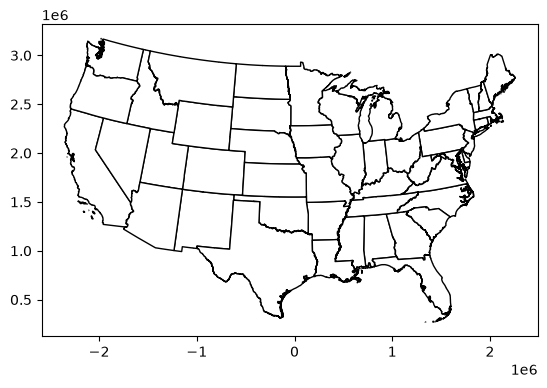

In [44]:
# getting the US census data

url_0 = "https://www2.census.gov/geo/tiger/GENZ2024/shp/" # url for census tiger data 
url_county = "cb_2024_us_county_500k.zip" # county level
url_state = "cb_2024_us_state_500k.zip" # state level 


### Code for county level data 

# counties = gpd.read_file(url_0+url_county)
# nc_counties = counties.loc[counties["STATEFP"] == "37"].copy()
# nc_counties.plot(edgecolor="black", facecolor="white")

## remove Alaska, Hawaii and those other islands which makes mapping difficult, but life much nicer.  
states = gpd.read_file(url_0+url_state)
contiguous_us = states.loc[
    ~states["STUSPS"].isin(["AK", "HI", "PR", "VI", "GU", "MP", "AS"])
]

contiguous_us = contiguous_us.to_crs(epsg=5070)
contiguous_us.plot(edgecolor="black", facecolor="white")


In [45]:
# Load both species
bluebirds = pd.read_csv("eastern_bluebird_2025.csv")
starlings = pd.read_csv("european_starling_2025.csv")

# Combine the datasets
birds = pd.concat([bluebirds, starlings], ignore_index=True)

# Keep only the columns needed for mapping
birds = birds[
    ["queried_species", "decimalLongitude", "decimalLatitude"]
]

# Remove any rows with missing coordinates
birds = birds.dropna(
    subset=["decimalLongitude", "decimalLatitude"]
)

birds.head()


,queried_species,decimalLongitude,decimalLatitude
0,Eastern Bluebird,-77.037061,39.191627
1,Eastern Bluebird,-84.493370,33.953663
2,Eastern Bluebird,-96.368195,30.638145
3,Eastern Bluebird,-97.699178,30.243922
4,Eastern Bluebird,-77.751662,37.448676


In [46]:

bird_points = gpd.GeoDataFrame(
    birds.copy(),
    geometry=gpd.points_from_xy(
        birds["decimalLongitude"],  # x = longitude
        birds["decimalLatitude"]   # y = latitude
    ),
    crs="EPSG:4326"
)

# Reproject to match your contiguous US map
bird_points = bird_points.to_crs(epsg=5070)


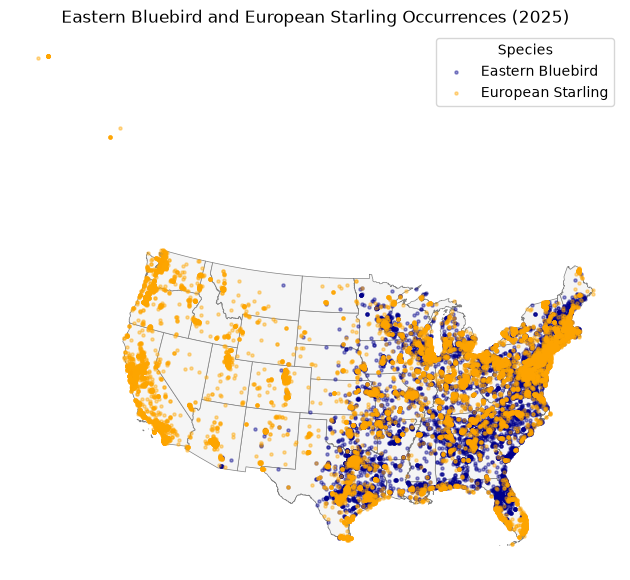

In [48]:

fig, ax = plt.subplots(figsize=(12, 7))

# Plot the contiguous United States
contiguous_us.plot(
    ax=ax,
    facecolor="whitesmoke",
    edgecolor="gray",
    linewidth=0.5
)

# Assign colors to each bird species
colors = {
    "Eastern Bluebird": "darkblue",
    "European Starling": "orange"
}

# Plot each species separately
for species, color in colors.items():
    bird_points.loc[
        bird_points["queried_species"] == species
    ].plot(
        ax=ax,
        color=color,
        markersize=5,
        alpha=0.4,
        label=species
    )

ax.set_title("Eastern Bluebird and European Starling Occurrences (2025)")
ax.legend(title="Species")
ax.set_axis_off()

plt.show()


In [49]:
points_by_state = gpd.sjoin(
    bird_points,
    contiguous_us[["NAME", "geometry"]],
    how="inner",
    predicate="within"
).drop(columns="index_right")

points_by_state.head()

,queried_species,decimalLongitude,decimalLatitude,geometry,NAME
0,Eastern Bluebird,-77.037061,39.191627,POINT (1612022.742 1957755.147),Maryland
1,Eastern Bluebird,-84.493370,33.953663,POINT (1053136.628 1273633.043),Georgia
2,Eastern Bluebird,-96.368195,30.638145,POINT (-35213.003 840308.418),Texas
3,Eastern Bluebird,-97.699178,30.243922,POINT (-163278.659 797910.194),Texas
4,Eastern Bluebird,-77.751662,37.448676,POINT (1589320.302 1754096.191),Virginia


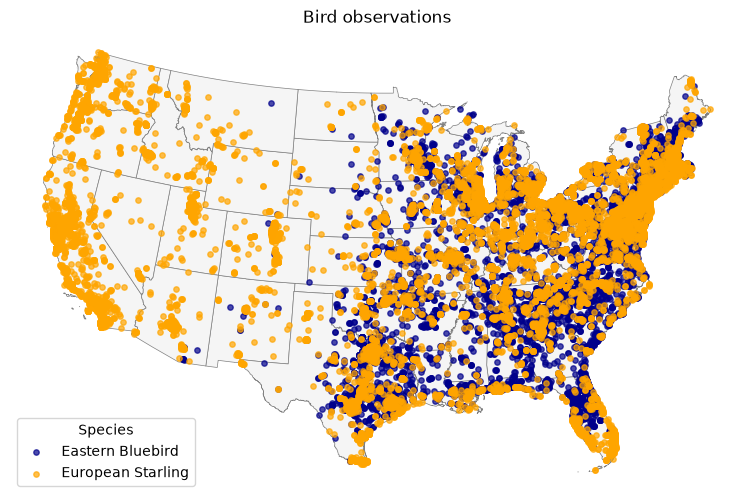

In [ ]:

fig, ax = plt.subplots(figsize=(12, 6)) # creating the fig and ax objects using plt
contiguous_us.plot(
    ax=ax,
    facecolor="whitesmoke",
    edgecolor="gray",
    linewidth=0.5
)

colors = {"Eastern Bluebird": "darkblue","European Starling": "orange"} 

for species, color in colors.items(): # 
    points_by_state.loc[
        points_by_state["queried_species"] == species
    ].plot(
        ax=ax,
        color=color,
        markersize=15,
        alpha=0.7,
        label=species
    )

ax.set_title("Bird observations")
ax.legend(title="Species")
ax.set_axis_off()

plt.show()

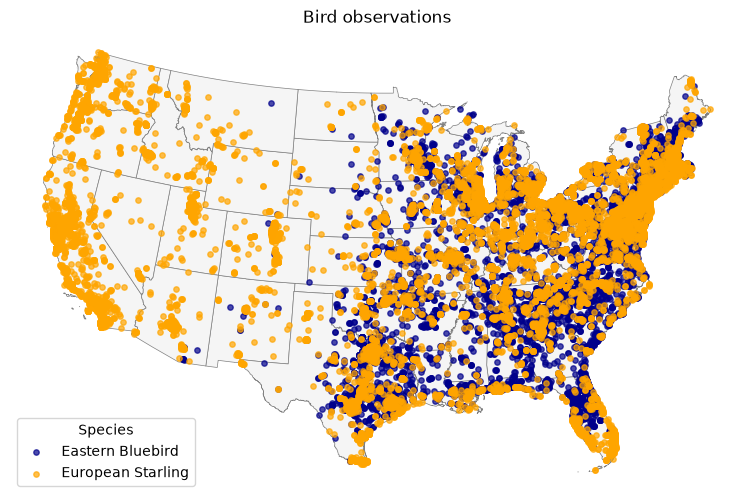

In [53]:
def pointMap(ax):

    # fig, ax = plt.subplots(figsize=(12, 6)) # creating the fig and ax objects using plt
    contiguous_us.plot(
        ax=ax,
        facecolor="whitesmoke",
        edgecolor="gray",
        linewidth=0.5
    )

    colors = {"Eastern Bluebird": "darkblue","European Starling": "orange"} 

    for species, color in colors.items(): # 
        points_by_state.loc[
            points_by_state["queried_species"] == species
        ].plot(
            ax=ax,
            color=color,
            markersize=15,
            alpha=0.7,
            label=species
        )

    ax.set_title("Bird observations")
    ax.legend(title="Species")
    ax.set_axis_off()
    return ax


fig, ax = plt.subplots(figsize=(12, 6)) 
ax =  pointMap(ax)
plt.show()

In [54]:
counts = (
    points_by_state
    .groupby(["NAME", "queried_species"])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=["Eastern Bluebird","European Starling"], fill_value=0)
)

# counts.head()

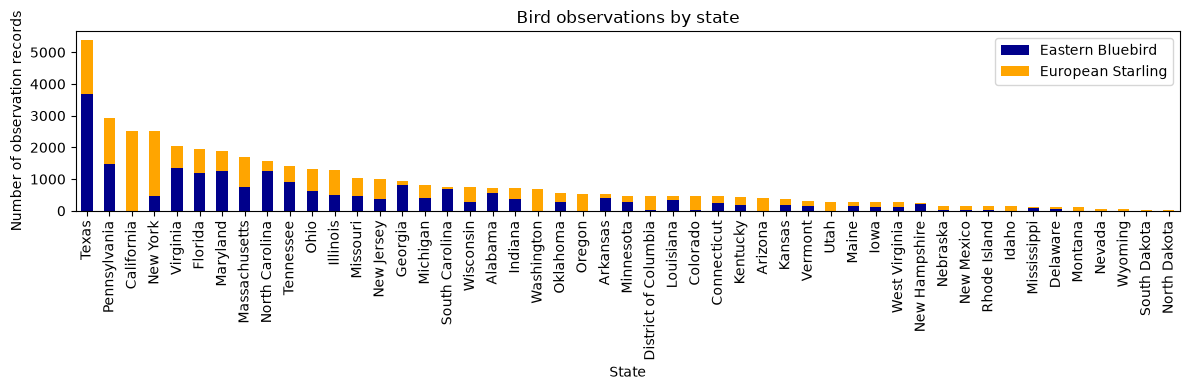

In [ ]:
def barPlot(ax, counts):
    counts = counts.loc[
        counts.sum(axis=1).sort_values(ascending=False).index
    ]

    counts[["Eastern Bluebird","European Starling"]].plot.bar(
        ax=ax,
        stacked=True,
        color=["darkblue", "orange"]
    )

    ax.set_xlabel("State")
    ax.set_ylabel("Number of observation records")
    ax.set_title("Bird observations by state")
    ax.legend(["Eastern Bluebird", "European Starling"])
    ax.tick_params(axis="x", labelrotation=90)

    return ax

fig, ax = plt.subplots(figsize=(12, 4)) 
ax = barPlot(ax,counts)
fig.tight_layout()
plt.show()



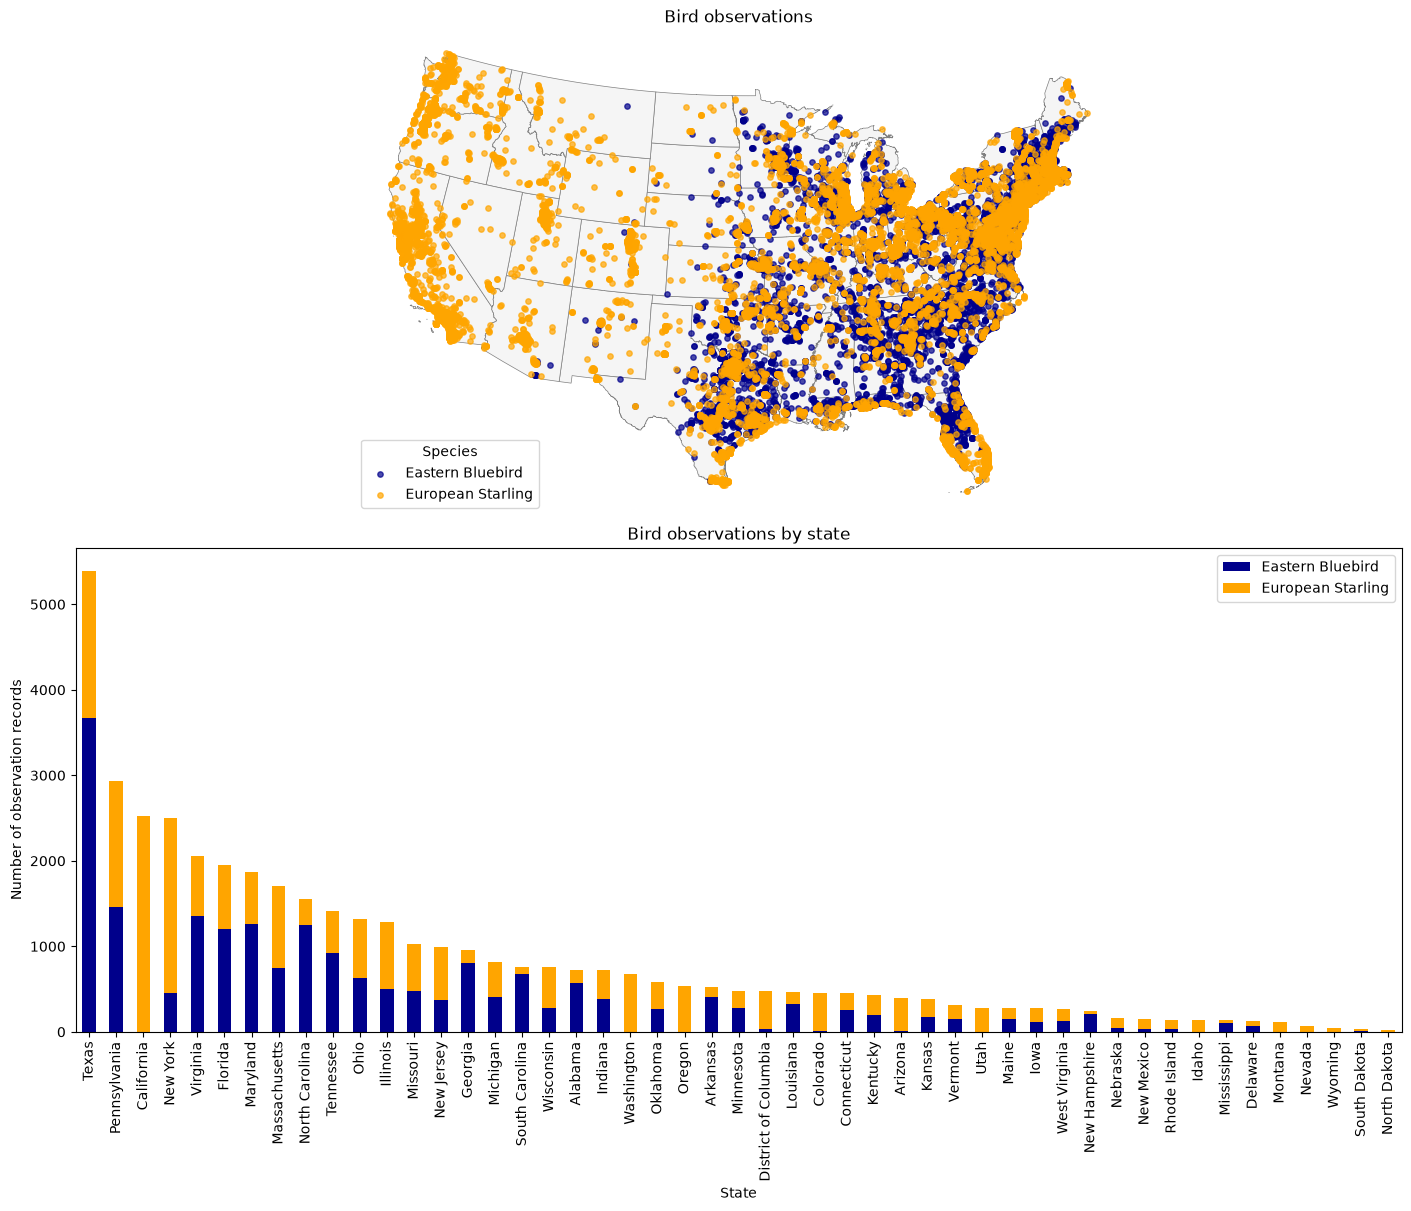

In [57]:
fig, axes = plt.subplots(
    2, 1,
    figsize=(14, 12),
    layout="constrained"
)

pointMap(axes[0])
barPlot(axes[1], counts)

plt.show()

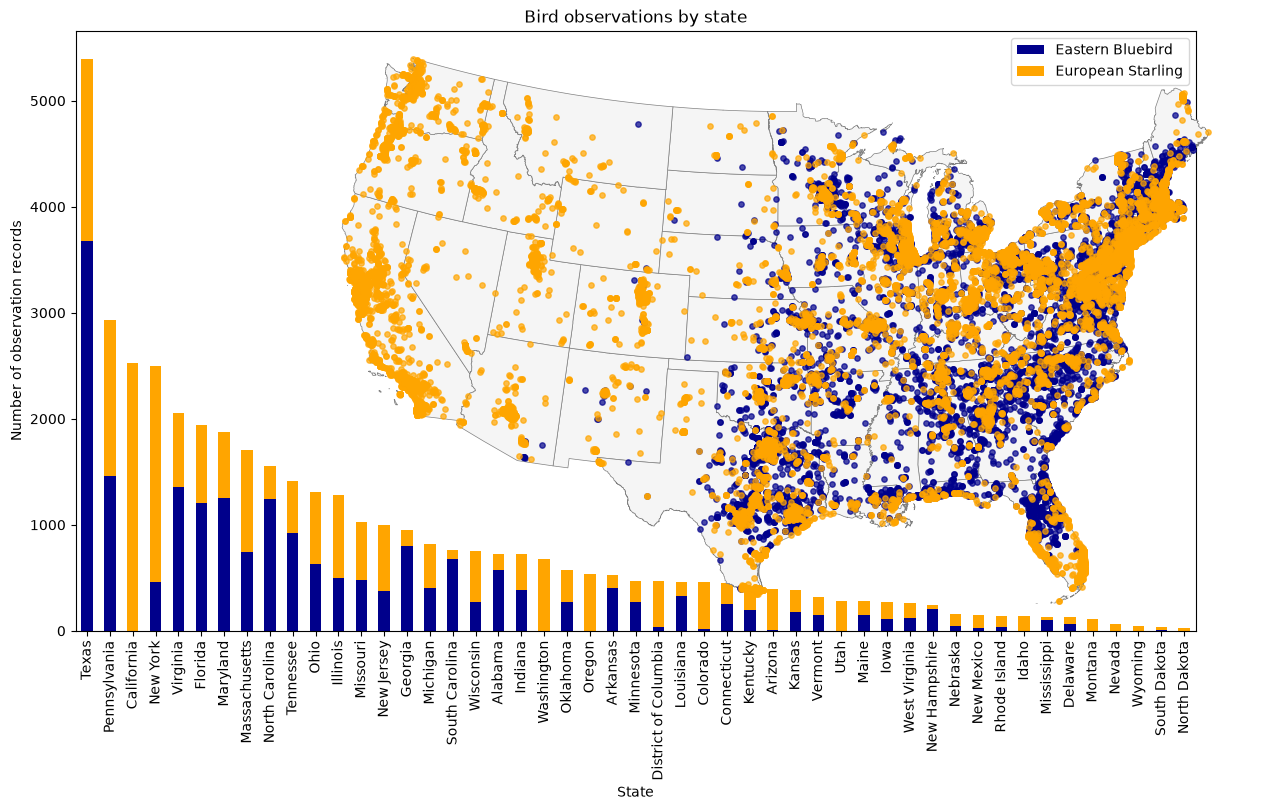

In [58]:
fig = plt.figure(figsize=(14, 8))

# [left, bottom, width, height], as fractions of the figure.
position_bar = [0.1, 0.15, 0.8, 0.75]
position_map= [0.20, 0.15, 0.8, 0.75]

ax_bar = fig.add_axes(position_bar, zorder=1)
barPlot(ax_bar, counts)

ax_map = fig.add_axes(position_map, zorder=2)
pointMap(ax_map)  # Match your function's arguments.

legend = ax_map.get_legend() # removing the legend
if legend is not None:
    legend.remove()

ax_map.set_title("") # removing the title 

# Make the upper layer transparent.
ax_map.set_facecolor("none")
ax_map.patch.set_alpha(0)
ax_map.set_axis_off()

plt.show()

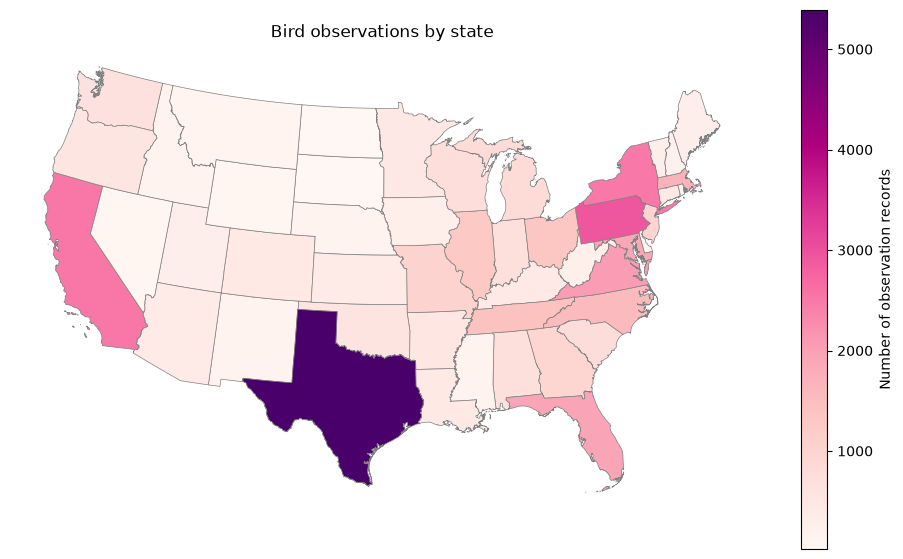

In [60]:
def choroplethMap(ax, contiguous_us, counts):
    # Total observations per state.
    totals = counts.sum(axis=1).rename("total")

    # Join totals to the state polygons.
    state_map = contiguous_us.merge(
        totals,
        left_on="NAME",
        right_index=True,
        how="left"
    )

    # States without records receive zero.
    state_map["total"] = state_map["total"].fillna(0)

    state_map.plot(
        column="total",
        cmap="RdPu", # This color was selected by me not Ai 
        edgecolor="gray",
        linewidth=0.5,
        legend=True,
        legend_kwds={"label": "Number of observation records"},
        ax=ax
    )

    ax.set_title("Bird observations by state")
    ax.set_axis_off()

    return ax

fig, ax = plt.subplots(figsize=(12, 7))

choroplethMap(ax, contiguous_us, counts)

plt.show()

In [61]:
%pip install mapclassify

   ---------------------------------------- 0.0/2.1 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.1 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.1 MB ? eta -:--:--
   ---- ----------------------------------- 0.3/2.1 MB ? eta -:--:--
   ---- ----------------------------------- 0.3/2.1 MB ? eta -:--:--
   --------- ------------------------------ 0.5/2.1 MB 560.6 kB/s eta 0:00:03
   --------- ------------------------------ 0.5/2.1 MB 560.6 kB/s eta 0:00:03
   -------------- ------------------------- 0.8/2.1 MB 645.6 kB/s eta 0:00:03
   -------------- ------------------------- 0.8/2.1 MB 645.6 kB/s eta 0:00:03
   ------------------- -------------------- 1.0/2.1 MB 674.3 kB/s eta 0:00:02
   ------------------- -------------------- 1.0/2.1 MB 674.3 kB/s eta 0:00:02
   ------------------------ --------------- 1.3/2.1 MB 604.5 kB/s eta 0:00:02
   ------------------------ --------------- 1.3/2.1 MB 604.5 kB/s eta 0:00:02
   ----------------------------

In [62]:
def choroplethEqual(ax, contiguous_us, counts):
    totals = counts.sum(axis=1).rename("total")

    state_map = contiguous_us.merge(
        totals, left_on="NAME", right_index=True, how="left"
    )
    state_map["total"] = state_map["total"].fillna(0)

    state_map.plot(
        column="total",
        scheme="equalinterval",
        k=5,
        cmap="RdPu",
        edgecolor="gray",
        linewidth=0.5,
        legend=True,
        legend_kwds={"title": "Observation records", "fontsize": 8},
        ax=ax
    )

    ax.set_title("Equal interval")
    ax.set_axis_off()
    return ax

def choroplethQuantiles(ax, contiguous_us, counts):
    totals = counts.sum(axis=1).rename("total")

    state_map = contiguous_us.merge(
        totals, left_on="NAME", right_index=True, how="left"
    )
    state_map["total"] = state_map["total"].fillna(0)

    state_map.plot(
        column="total",
        scheme="quantiles",
        k=5,
        cmap="RdPu",
        edgecolor="gray",
        linewidth=0.5,
        legend=True,
        legend_kwds={"title": "Observation records", "fontsize": 8},
        ax=ax
    )

    ax.set_title("Quantiles")
    ax.set_axis_off()
    return ax

def choroplethNatural(ax, contiguous_us, counts):
    totals = counts.sum(axis=1).rename("total")

    state_map = contiguous_us.merge(
        totals, left_on="NAME", right_index=True, how="left"
    )
    state_map["total"] = state_map["total"].fillna(0)

    state_map.plot(
        column="total",
        scheme="fisherjenks",
        k=5,
        cmap="RdPu",
        edgecolor="gray",
        linewidth=0.5,
        legend=True,
        legend_kwds={"title": "Observation records", "fontsize": 8},
        ax=ax
    )

    ax.set_title("Natural breaks (Fisher–Jenks)")
    ax.set_axis_off()
    return ax

c:\Users\athen\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\geopandas\plotting.py:746: UserWarning: Numba not installed. Using slow pure python version.
  binning = mapclassify.classify(


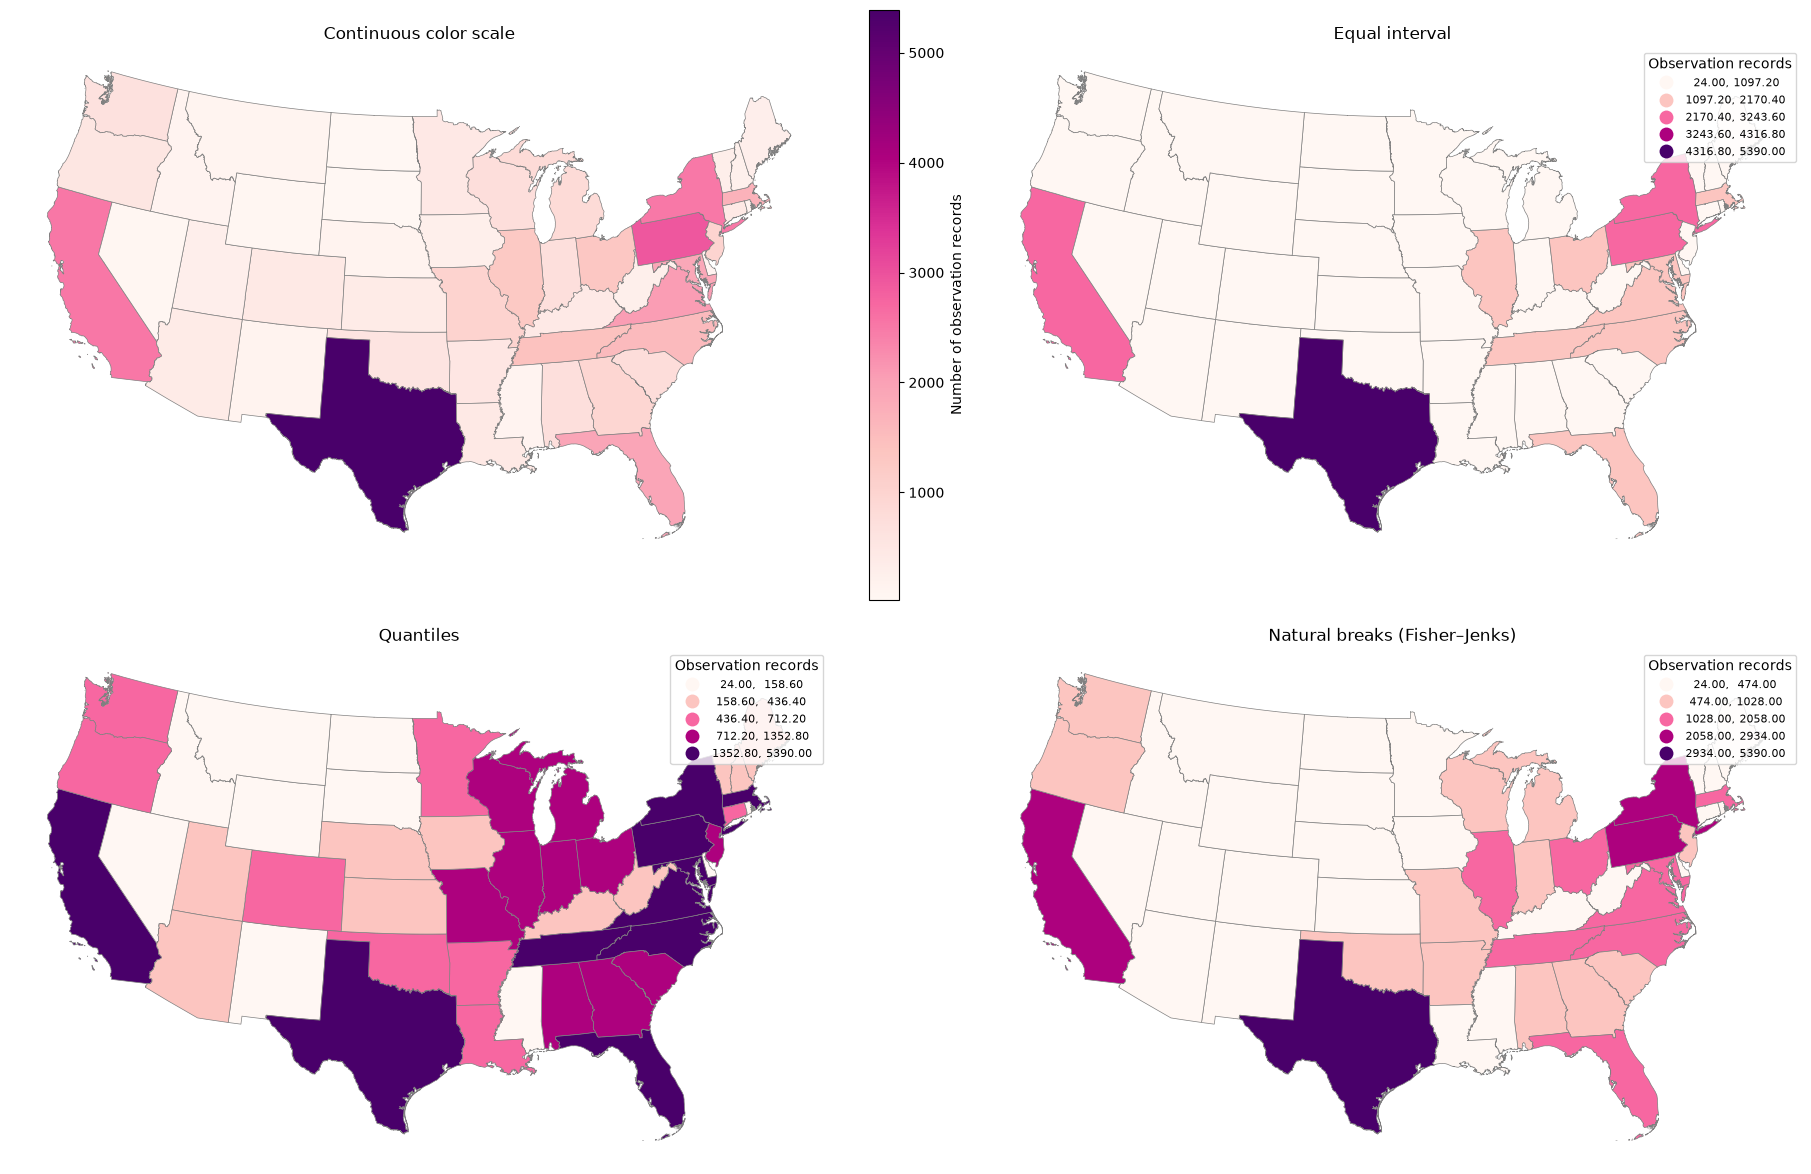

In [63]:
fig, axes = plt.subplots(
    2, 2,
    figsize=(18, 12),
    layout="constrained"
)

choroplethMap(axes[0, 0], contiguous_us, counts)
axes[0, 0].set_title("Continuous color scale")

choroplethEqual(axes[0, 1], contiguous_us, counts)
choroplethQuantiles(axes[1, 0], contiguous_us, counts)
choroplethNatural(axes[1, 1], contiguous_us, counts)

# fig.savefig("mulberry_classification.png", dpi=300, bbox_inches="tight")
# fig.savefig("mulberry_classification.pdf", bbox_inches="tight")

plt.show()

Eastern Bluebird positive-count median: 275.0
European Starling positive-count median: 233.0


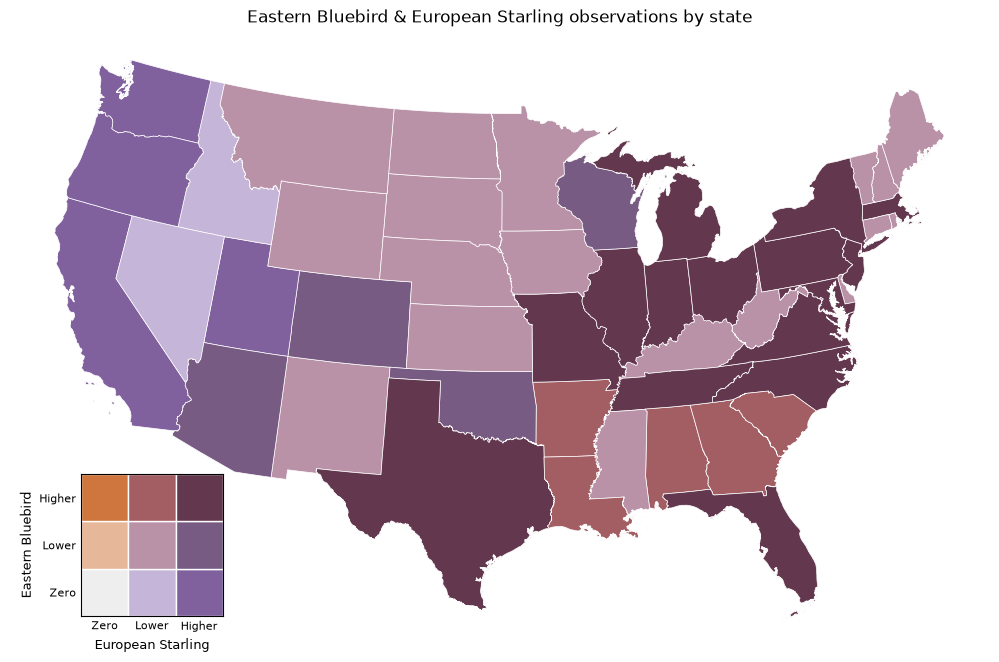

In [65]:
## Bivariate plot code generated using AI

import numpy as np
from matplotlib.patches import Rectangle

# Attach each species' counts to the state polygons.
bivariate = contiguous_us.merge(
    counts,
    left_on="NAME",
    right_index=True,
    how="left"
)

species = ["Eastern Bluebird","European Starling"]
bivariate[species] = bivariate[species].fillna(0)

# Classify each species:
# 0 = no records
# 1 = positive count at or below the positive-count median
# 2 = count above that median
for name in species:
    values = bivariate[name]
    median = values.loc[values > 0].median()

    bivariate[name + "_class"] = np.select(
        [values == 0, values <= median],
        [0, 1],
        default=2
    )

    print(name, "positive-count median:", median)


palette = np.array([
    ["#eeeeee", "#c5b5d8", "#80619e"],
    ["#e6b899", "#b992a8", "#785b82"],
    ["#cf763e", "#a35e63", "#63384f"]
])

bivariate["color"] = [
    palette[red, white]
    for red, white in zip(
        bivariate["Eastern Bluebird_class"],
        bivariate["European Starling_class"]
    )
]

fig, ax = plt.subplots(figsize=(13, 8))

bivariate.plot(
    color=bivariate["color"],
    edgecolor="white",
    linewidth=0.5,
    ax=ax
)

ax.set_title("Eastern Bluebird & European Starling observations by state")
ax.set_axis_off()

# Add a 3 × 3 bivariate legend.
legend_ax = ax.inset_axes([0.05, 0.05, 0.19, 0.23])

for red in range(3):
    for white in range(3):
        legend_ax.add_patch(
            Rectangle(
                (white, red), 1, 1,
                facecolor=palette[red, white],
                edgecolor="white"
            )
        )

legend_ax.set_xlim(0, 3)
legend_ax.set_ylim(0, 3)
legend_ax.set_aspect("equal")

legend_ax.set_xticks([0.5, 1.5, 2.5])
legend_ax.set_yticks([0.5, 1.5, 2.5])
legend_ax.set_xticklabels(["Zero", "Lower", "Higher"], fontsize=8)
legend_ax.set_yticklabels(["Zero", "Lower", "Higher"], fontsize=8)

legend_ax.set_xlabel("European Starling", fontsize=9)
legend_ax.set_ylabel("Eastern Bluebird", fontsize=9)
legend_ax.tick_params(length=0)

plt.show()

Add a short description about the benefits and limitations of classification schemes for studying species distribution in the landscape.  

The different classification schemes help demonstrate different representations for the data and can demonstrate certain ecological phenomena like species niches and ranges. It's also helpful for showing the differences in ranges between the species. However, the difference classification schemes make things a little complicated, particularly quantile, as it represents vastly different species concentration data when compared with the other maps and classification can skew the map interpretation. 